# Histogram Equalization: HE vs AHE vs CLAHE

Testing three contrast enhancement techniques on `gizmo.jpg` and comparing fidelity using PSNR and SSIM.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim

### 1. Load image
Equalization works on brightness, so we load the image in grayscale.

In [2]:
img = cv2.imread('gizmo.jpg', cv2.IMREAD_GRAYSCALE)
print(f"Loaded gizmo.jpg: {img.shape[1]}x{img.shape[0]} px")

Loaded gizmo.jpg: 3072x4080 px


### 2. Apply enhancements
- **HE**: Stretches contrast across the whole image at once.
- **AHE**: Works locally in 8x8 blocks, but doesn't limit contrast (can boost noise).
- **CLAHE**: Same as AHE, but clips spikes (`clipLimit=2.0`) to keep noise under control.

In [3]:
# Standard global HE
img_he = cv2.equalizeHist(img)

# AHE (CLAHE with a high clip limit to simulate unconstrained local equalization)
ahe = cv2.createCLAHE(clipLimit=40.0, tileGridSize=(8, 8))
img_ahe = ahe.apply(img)

# CLAHE
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
img_clahe = clahe.apply(img)

### 3. PSNR & SSIM Scores
- **PSNR**: Measures how much the pixel values drifted from the original. Note: a lower score doesn't mean a worse picture here, just that contrast was changed more aggressively.
- **SSIM**: Measures structural similarity (perceived quality and structure preservation) between -1 and 1 (1 being identical).

In [4]:
psnr_he = cv2.PSNR(img, img_he)
psnr_ahe = cv2.PSNR(img, img_ahe)
psnr_clahe = cv2.PSNR(img, img_clahe)

ssim_he = ssim(img, img_he)
ssim_ahe = ssim(img, img_ahe)
ssim_clahe = ssim(img, img_clahe)

print(f"PSNR HE:    {psnr_he:.2f} dB | SSIM HE:    {ssim_he:.4f}")
print(f"PSNR AHE:   {psnr_ahe:.2f} dB | SSIM AHE:   {ssim_ahe:.4f}")
print(f"PSNR CLAHE: {psnr_clahe:.2f} dB | SSIM CLAHE: {ssim_clahe:.4f}")

PSNR HE:    15.54 dB | SSIM HE:    0.7203
PSNR AHE:   13.15 dB | SSIM AHE:   0.4806
PSNR CLAHE: 23.05 dB | SSIM CLAHE: 0.8930


### 4. Visual comparison & histograms

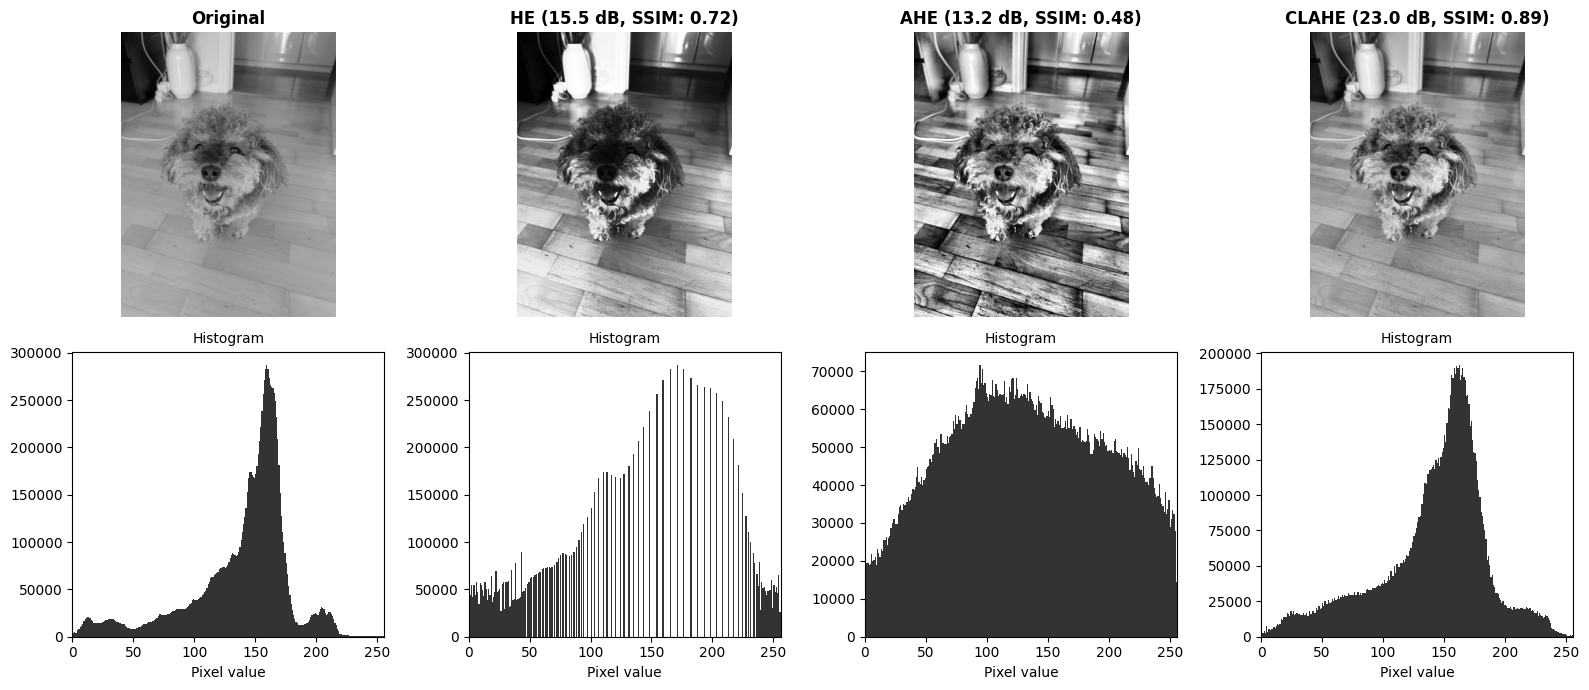

In [5]:
items = [
    ("Original", img, None, None),
    (f"HE ({psnr_he:.1f} dB, SSIM: {ssim_he:.2f})", img_he, psnr_he, ssim_he),
    (f"AHE ({psnr_ahe:.1f} dB, SSIM: {ssim_ahe:.2f})", img_ahe, psnr_ahe, ssim_ahe),
    (f"CLAHE ({psnr_clahe:.1f} dB, SSIM: {ssim_clahe:.2f})", img_clahe, psnr_clahe, ssim_clahe)
]

fig, axes = plt.subplots(2, 4, figsize=(16, 7))

for i, (title, pic, *_) in enumerate(items):
    # Image
    axes[0, i].imshow(pic, cmap='gray')
    axes[0, i].set_title(title, fontsize=12, fontweight='bold')
    axes[0, i].axis('off')
    
    # Histogram
    axes[1, i].hist(pic.ravel(), bins=256, range=[0, 256], color='#333333')
    axes[1, i].set_xlim([0, 256])
    axes[1, i].set_title('Histogram', fontsize=10)
    axes[1, i].set_xlabel('Pixel value')

plt.tight_layout()
plt.show()